<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Why the neighbourhood prior rescues extrasomatic uRNA whose gene is absent from the soma.
> - **Manuscript panels:** Reviewer response (source-score neighbourhood)
> - **Inputs:** Notebook 10 outputs
> - **Outputs:** Figures G1-G3
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Why the neighborhood prior rescues extrasomatic uRNA (reviewer point 2, xenium_msbrain_5k)

**Reviewer concern.** Requiring the source cell to express a transcript's gene in its soma biases against extrasomatic RNA:
a transcript sitting in a distal protrusion whose soma has no (or too few) counts of that gene can't be assigned to that soma;
it goes to the residual ("bias") term or to a farther cell that happens to express the gene.

**What the code does** (`tl.urna_source_score` → numba kernel `_core_scoring_engine_chunk`, `troutpy/tl/source_cell.py`).
For each extracellular transcript $i$ and each candidate shell point of cell $c$ within `max_dist`:

$$w_{ic} = \frac{|Q_i \cap E_c|}{|Q_i|}\, e^{-\lambda d_{ic}}, \qquad s_{ic} = \frac{w_{ic}}{\sum_{c'} w_{ic'} + r}$$

* $E_c$ = genes with non-zero counts in cell $c$ (sparsity pattern of `X`).
* $Q_i$ = genes of the $k_i$ nearest extracellular transcripts (including $i$ itself), with
  $k_i = \mathrm{clip}\!\left(1 + (k_{max}-1)\frac{e_i - e_{amb}}{e_{sig} - e_{amb}}, 1, k_{max}\right)$, where $e_i$ is `enrichment_over_random`.
  Ambient-level transcripts get $k_i = 1$; dense clouds get up to $k_{max}=10$.
* $r$ = residual (bias term, 0.1).

With $k_i = 1$ (**no neighborhood**, the original logic) $Q_i = \{g_i\}$, so $w_{ic} = 0$ for any cell lacking $g_i$; this is exactly the reviewer's failure mode.
With the neighborhood a cell that lacks $g_i$ but expresses the genes co-localizing with $i$ still gets weight.

All numbers below come from the run in `source_score_neighborhood_comparison.py` (notebook 10), where `with_neighbors` (max_k=10)
reproduces the production λ=0.5 result exactly and `no_neighbors` sets max_k=1 with everything else identical.

**Sections**
1. A worked example on a real transcript (mechanism).
2. Ground truth: held-out peripheral transcripts whose gene is **absent from the remaining soma**, the reviewer's scenario.
3. Real data: how often the no-neighbor logic dumps transcripts into the bias term or onto distant cells, incl. neurite-localized mRNAs.
4. Cost and limits.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import pyarrow.dataset as pads
from scipy.spatial import cKDTree

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sns.set_style('ticks')

data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
res_dir = data_dir / "source_score_neighborhood_comparison"
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/source_score_neighborhood")
saving_path.mkdir(parents=True, exist_ok=True)

info = json.load(open(res_dir / "run_info.json"))
P = info['params']
cell_types = np.array(info['cell_types'])
MODES = ['with_neighbors', 'no_neighbors']
MODE_LABEL = {'with_neighbors': 'with neighborhood (max_k=10)', 'no_neighbors': 'no neighborhood (max_k=1)'}
MODE_COL = {'with_neighbors': '#c0392b', 'no_neighbors': '#2c7fb8'}
NEURON_TYPES = [t for t in cell_types if any(s in t for s in ['CA1', 'CA3', 'DG', 'neurons', 'Cajal', 'Neuroblast'])]

table = ad.read_zarr(data_dir / "data_annotated.zarr" / "tables" / "table")
assert list(table.obs['cell_id'].astype(str).str.strip()) == info['cell_ids']
ct_cat = table.obs['cell_type'].astype('category')
ct_colors = dict(zip(ct_cat.cat.categories, table.uns['cell_type_colors']))
X = table.X.tocsr() if hasattr(table.X, 'tocsr') else table.X
var_names = np.array(table.var_names)
print(P, '\nambient floor:', info['ambient_floor'])
print('neuronal types:', NEURON_TYPES)

{'max_dist': 200.0, 'lmbda': 0.5, 'max_k': 10, 'signal_threshold': 10.0, 'residual': 0.1, 'chunk_size': 100000} 
ambient floor: 4.192010291567437
neuronal types: ['CA1-2', 'CA3', 'Cajal-Retzius', 'DG', 'EXC neurons Thal.', 'EXC. neurons CTX', 'INH neurons', 'INH neurons CP', 'SGZ Neuroblasts']


## 1. Worked example: a Shank3 transcript next to a neuron that doesn't express Shank3
*Shank3* is a classic dendritically localized postsynaptic mRNA. We pick a real extracellular *Shank3* transcript in a dense uRNA cloud
($k=10$) that lies <1 µm from a neuron whose segmented soma has **zero** *Shank3* counts. We recompute the kernel weights for this transcript
in plain Python (same formula, same shell definition) and check they match the stored run.

In [2]:
real = pd.read_parquet(res_dir / "real_per_transcript.parquet")
EX_TX = 10539292                      # chosen by: k=10, with-nbhd parent doesn't express gene, d<3 µm vs >12 µm without
ex = real.loc[real['tx_index'] == EX_TX].iloc[0]
print(ex[['gene', 'x', 'y', 'k_prod', 'enrichment',
          'with_neighbors__parent_row', 'with_neighbors__dist', 'with_neighbors__score', 'with_neighbors__gene_expr_in_parent',
          'no_neighbors__parent_row', 'no_neighbors__dist', 'no_neighbors__score']].to_string())

# Transcripts around the example (padding >> 1/lambda, so truncated shells far away carry ~0 weight)
PAD = 80
x0, y0 = ex.x, ex.y
dset = pads.dataset(str(data_dir / "data_annotated.zarr/points/transcripts/points.parquet"), format='parquet')
flt = (pads.field('x') >= x0 - PAD) & (pads.field('x') <= x0 + PAD) & (pads.field('y') >= y0 - PAD) & (pads.field('y') <= y0 + PAD)
win = dset.to_table(columns=['x', 'y', 'gene', 'cell_id', '__null_dask_index__'], filter=flt).to_pandas(ignore_metadata=True)
win['cell_id'] = win['cell_id'].astype(str).str.strip()
win['gene'] = win['gene'].astype(str)
cid2row = {c: i for i, c in enumerate(info['cell_ids'])}
win['row'] = win['cell_id'].map(cid2row)
intra = win.dropna(subset=['row']).copy(); intra['row'] = intra['row'].astype(int)
extra = win[win['row'].isna()].reset_index(drop=True)
gene2idx = {g: i for i, g in enumerate(var_names)}

# Shell = the min/max x and min/max y transcript of each cell (as in production)
g = intra.groupby('row')
shell = intra.loc[pd.concat([g['x'].idxmin(), g['x'].idxmax(), g['y'].idxmin(), g['y'].idxmax()]).unique()]
shell_xy, shell_row = shell[['x', 'y']].values, shell['row'].values

q = np.where(extra['__null_dask_index__'].values == EX_TX)[0][0]
_, nn = cKDTree(extra[['x', 'y']].values).query(extra.loc[q, ['x', 'y']].values.astype(float), k=P['max_k'])
context = {'no_neighbors': [extra.loc[q, 'gene']], 'with_neighbors': list(extra.loc[nn[:int(ex.k_prod)], 'gene'])}
print('\ncontext genes (k=%d):' % ex.k_prod, context['with_neighbors'])

def kernel(qgenes):
    qi = [gene2idx[g] for g in qgenes if g in gene2idx]
    d = np.hypot(shell_xy[:, 0] - ex.x, shell_xy[:, 1] - ex.y)
    keep = d <= P['max_dist']
    rows, d = shell_row[keep], d[keep]
    match = np.array([np.isin(qi, X[r].indices).sum() for r in rows]) / len(qi)
    w = match * np.exp(-P['lmbda'] * d)
    s = w / (w.sum() + P['residual'])
    df = pd.DataFrame({'row': rows, 'dist': d, 'match': match, 'score': s})
    best = df.loc[df['score'].idxmax()]
    per_cell = df.groupby('row').agg(dist=('dist', 'min'), match=('match', 'first'), mass=('score', 'sum'))
    return best, per_cell, P['residual'] / (w.sum() + P['residual'])

ker = {m: kernel(context[m]) for m in MODES}
for m in MODES:
    best, _, bias = ker[m]
    print(f"{m:15s} best parent row {int(best.row)} (stored {int(ex[m + '__parent_row'])}), score {best.score:.4f} "
          f"(stored {ex[m + '__score']:.4f}), d={best.dist:.2f} µm, mass on bias term {bias:.3f}")
    assert int(best.row) == int(ex[m + '__parent_row'])

gene                                       Shank3
x                                      4497.65625
y                                      2176.59375
k_prod                                         10
enrichment                              10.899227
with_neighbors__parent_row                   6314
with_neighbors__dist                     0.494106
with_neighbors__score                    0.861505
with_neighbors__gene_expr_in_parent         False
no_neighbors__parent_row                     6294
no_neighbors__dist                      20.922348
no_neighbors__score                      0.000286



context genes (k=10): ['Shank3', 'Pak1', 'Enah', 'Mapk1', 'Lingo1', 'Preb', 'Camk2d', 'Rab7', 'Stxbp1', 'Adgrb1']


with_neighbors  best parent row 6314 (stored 6314), score 0.8615 (stored 0.8615), d=0.49 µm, mass on bias term 0.138
no_neighbors    best parent row 6294 (stored 6294), score 0.0003 (stored 0.0003), d=20.92 µm, mass on bias term 0.999


In [3]:
shank = gene2idx[ex.gene]
cells_tbl = ker['with_neighbors'][1][['dist', 'match', 'mass']].rename(columns={'match': 'frac context genes expressed', 'mass': 'mass WITH nbhd'})
cells_tbl['mass NO nbhd'] = ker['no_neighbors'][1]['mass']
cells_tbl['cell type'] = table.obs['cell_type'].values[cells_tbl.index]
cells_tbl[f'{ex.gene} detected in soma'] = [shank in X[r].indices for r in cells_tbl.index]   # same 'expressed' test as the kernel
cells_tbl['n genes detected'] = np.diff(X.indptr)[cells_tbl.index]
cells_tbl = cells_tbl.sort_values('dist')
cells_tbl.head(8).round(3)

,dist,frac context genes expressed,mass WITH nbhd,mass NO nbhd,cell type,Shank3 detected in soma,n genes detected
row,,,,,,,
6314,0.494000,0.8,0.862,0.0,INH neurons,False,1373
6294,20.922001,0.9,0.000,0.0,Astrocytes,True,945
6315,21.330999,0.7,0.000,0.0,INH neurons,False,1154
6293,23.038000,0.9,0.000,0.0,CA3,True,1361
6330,23.052000,0.9,0.000,0.0,Astrocytes,True,1088
6295,27.351999,0.6,0.000,0.0,CA3,False,660
9061,31.087999,0.1,0.000,0.0,Endothelial,False,384
6305,31.566999,0.7,0.000,0.0,Oligodendrocytes,True,836


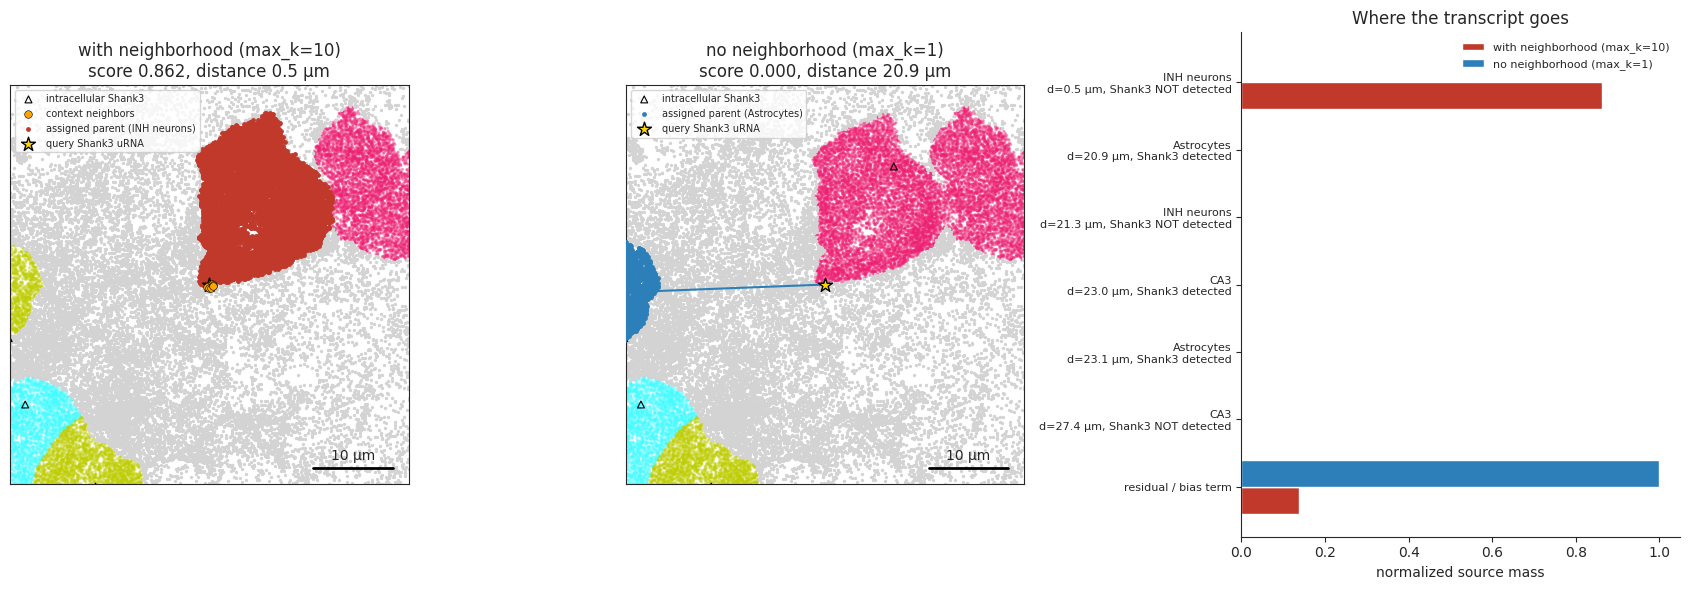

In [4]:
fig = plt.figure(figsize=(17, 6))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.1])
R = 25
near = intra[((intra.x - ex.x).abs() < R + 5) & ((intra.y - ex.y).abs() < R + 5)]
ext_near = extra[((extra.x - ex.x).abs() < R + 5) & ((extra.y - ex.y).abs() < R + 5)]
for j, m in enumerate(MODES):
    ax = fig.add_subplot(gs[j])
    ax.scatter(near.x, near.y, s=2, c=[ct_colors[t] for t in table.obs['cell_type'].values[near.row]], alpha=0.35, rasterized=True)
    ax.scatter(ext_near.x, ext_near.y, s=2, c='lightgrey', rasterized=True)
    hasg = near[near.gene == ex.gene]
    ax.scatter(hasg.x, hasg.y, s=25, marker='^', facecolor='none', edgecolor='k', lw=0.8, label=f'intracellular {ex.gene}')
    if m == 'with_neighbors':
        ctx = extra.loc[nn[1:int(ex.k_prod)]]
        ax.scatter(ctx.x, ctx.y, s=30, c='orange', edgecolor='k', lw=0.4, zorder=6, label='context neighbors')
    best_row = int(ex[m + '__parent_row'])
    bc = near[near.row == best_row]
    ax.scatter(bc.x, bc.y, s=6, c=MODE_COL[m], zorder=3, label=f'assigned parent ({table.obs["cell_type"].values[best_row]})')
    ax.plot([ex.x, bc.x.mean()], [ex.y, bc.y.mean()], '-', color=MODE_COL[m], lw=1.5)
    ax.scatter([ex.x], [ex.y], s=110, marker='*', c='gold', edgecolor='k', zorder=5, label=f'query {ex.gene} uRNA')
    ax.set(xlim=(ex.x - R, ex.x + R), ylim=(ex.y - R, ex.y + R), aspect='equal', xticks=[], yticks=[],
           title=f"{MODE_LABEL[m]}\nscore {ex[m + '__score']:.3f}, distance {ex[m + '__dist']:.1f} µm")
    ax.plot([ex.x + R - 12, ex.x + R - 2], [ex.y - R + 2] * 2, 'k-', lw=2); ax.text(ex.x + R - 7, ex.y - R + 3, '10 µm', ha='center')
    ax.legend(loc='upper left', fontsize=7, frameon=True)

ax = fig.add_subplot(gs[2])
top = cells_tbl.head(6)
lab = [f"{table.obs['cell_type'].values[r]}\nd={d:.1f} µm, {ex.gene} {'detected' if n else 'NOT detected'}" for r, d, n in zip(top.index, top['dist'], top[f'{ex.gene} detected in soma'])]
yy = np.arange(len(top) + 1)
ax.barh(yy[:-1] + 0.2, top['mass WITH nbhd'], 0.4, color=MODE_COL['with_neighbors'], label=MODE_LABEL['with_neighbors'])
ax.barh(yy[:-1] - 0.2, top['mass NO nbhd'].fillna(0), 0.4, color=MODE_COL['no_neighbors'], label=MODE_LABEL['no_neighbors'])
ax.barh(yy[-1] + 0.2, ker['with_neighbors'][2], 0.4, color=MODE_COL['with_neighbors'])
ax.barh(yy[-1] - 0.2, ker['no_neighbors'][2], 0.4, color=MODE_COL['no_neighbors'])
ax.set_yticks(yy); ax.set_yticklabels(lab + ['residual / bias term'], fontsize=8); ax.invert_yaxis()
ax.set(xlabel='normalized source mass', title='Where the transcript goes'); ax.legend(frameon=False, fontsize=8)
sns.despine(ax=ax); plt.tight_layout()
plt.savefig(saving_path / 'G1_worked_example_shank3.pdf', dpi=300); plt.show()

**Reading the example.** Without the neighborhood every nearby cell that lacks *Shank3* has weight 0, so ~all mass falls onto the residual
(bias) term and the nominal "best parent" is a cell ~20 µm away with a negligible score: the transcript is effectively lost, which is the reviewer's scenario.
With the neighborhood the transcript's co-localized genes are matched against the adjacent neuron, which expresses most of them,
and the transcript is assigned to it with high confidence even though its soma has no *Shank3* counts.

## 2. Ground truth: the reviewer's scenario, simulated
Benchmark from notebook 10 (*truncated* expression): for 10% of cells (3 seeds), the outer 30% of their transcripts are moved into the extracellular
pool and the cell's expression is rebuilt **without** them. For about half of these held-out transcripts the gene is then
**absent from the remaining soma**, i.e. the gene is only detected in the cell's periphery. This is the reviewer's case:
a transcript whose true source soma has no local count of its gene. Below we stratify by that.

In [5]:
bench = pd.concat([pd.read_parquet(p) for p in sorted(res_dir.glob('benchmark_seed*_truncated.parquet'))], ignore_index=True)
KS = info['bench']['max_k']
bench['gene_absent_from_soma'] = ~bench['gene_expr_in_true_after_holdout']
bench['true_ct'] = cell_types[bench['true_type']]
bench['neuron'] = bench['true_ct'].isin(NEURON_TYPES)
for k in KS:
    bench[f'k{k}__parent_ok'] = bench[f'k{k}__parent_row'] == bench['true_row']
    bench[f'k{k}__type_ok'] = bench[f'k{k}__type'] == bench['true_type']
    bench[f'k{k}__lost'] = bench[f'k{k}__score'] < 0.2          # below the min_score used in the paper figures
print(f"{len(bench):,} held-out queries; gene absent from soma after hold-out:",
      bench.groupby('density')['gene_absent_from_soma'].mean().round(3).to_dict())

rows = []
for (dens, seed, absent), g in bench.groupby(['density', 'seed', 'gene_absent_from_soma']):
    for k in KS:
        rows.append(dict(density=dens, seed=seed, absent=absent, max_k=k, parent_acc=g[f'k{k}__parent_ok'].mean(),
                         type_acc=g[f'k{k}__type_ok'].mean(), true_type_mass=g[f'k{k}__true_type_frac'].fillna(0).mean(),
                         lost=g[f'k{k}__lost'].mean()))
strat = pd.DataFrame(rows)
strat.to_csv(saving_path / 'G2_benchmark_gene_absent_strata.csv', index=False)
strat[strat.max_k.isin([1, 10])].groupby(['density', 'absent', 'max_k'])[['parent_acc', 'type_acc', 'true_type_mass', 'lost']].agg(['mean', 'std']).round(3)

1,649,854 held-out queries; gene absent from soma after hold-out: {0.2: 0.517, 1.0: 0.517}


parent_acc        type_acc        true_type_mass         \
                           mean    std     mean    std           mean    std   
density absent max_k                                                           
0.2     False  1          0.759  0.016    0.959  0.002          0.927  0.003   
               10         0.673  0.017    0.945  0.002          0.904  0.003   
        True   1          0.000  0.000    0.609  0.005          0.603  0.005   
               10         0.455  0.010    0.841  0.005          0.807  0.005   
1.0     False  1          0.758  0.015    0.959  0.002          0.927  0.003   
               10         0.672  0.017    0.945  0.002          0.904  0.003   
        True   1          0.000  0.000    0.609  0.007          0.603  0.008   
               10         0.451  0.012    0.838  0.007          0.806  0.006   

                       lost         
                       mean    std  
density absent max_k                
0.2     False  1      0.016  0.002  
               10     0.044  0.004  
        True   1      0.533  0.007  
               10     0.170  0.003  
1.0     False  1      0.016  0.002  
               10     0.044  0.004  
        True   1      0.531  0.010  
               10     0.170  0.005

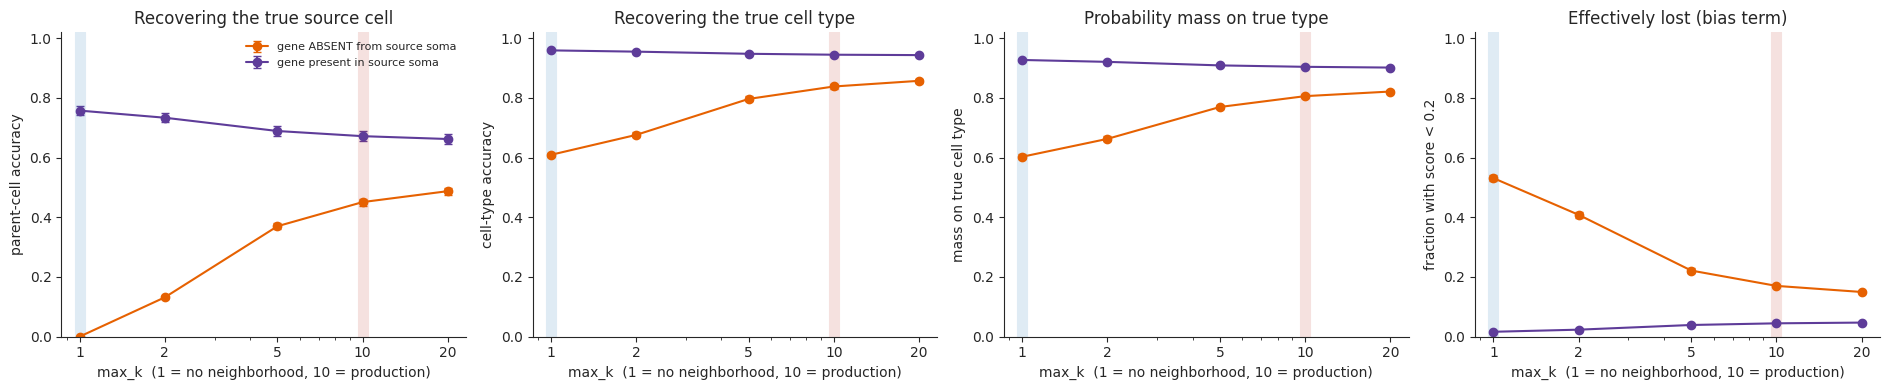

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
d1 = strat[strat.density == 1.0]
for absent, col, lab in [(True, '#e66101', 'gene ABSENT from source soma'), (False, '#5e3c99', 'gene present in source soma')]:
    for ax, met, yl in zip(axes, ['parent_acc', 'type_acc', 'true_type_mass', 'lost'],
                           ['parent-cell accuracy', 'cell-type accuracy', 'mass on true cell type', 'fraction with score < 0.2']):
        s = d1[d1.absent == absent].groupby('max_k')[met].agg(['mean', 'std'])
        ax.errorbar(s.index, s['mean'], yerr=s['std'], fmt='o-', color=col, capsize=3, label=lab)
        ax.set(xscale='log', xticks=KS, xticklabels=KS, xlabel='max_k  (1 = no neighborhood, 10 = production)', ylabel=yl, ylim=(0, 1.02))
for ax in axes:
    ax.axvline(1, color=MODE_COL['no_neighbors'], lw=8, alpha=0.15); ax.axvline(10, color=MODE_COL['with_neighbors'], lw=8, alpha=0.15)
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title('Recovering the true source cell'); axes[1].set_title('Recovering the true cell type')
axes[2].set_title('Probability mass on true type'); axes[3].set_title('Effectively lost (bias term)')
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'G2_benchmark_gene_absent_maxk.pdf'); plt.show()

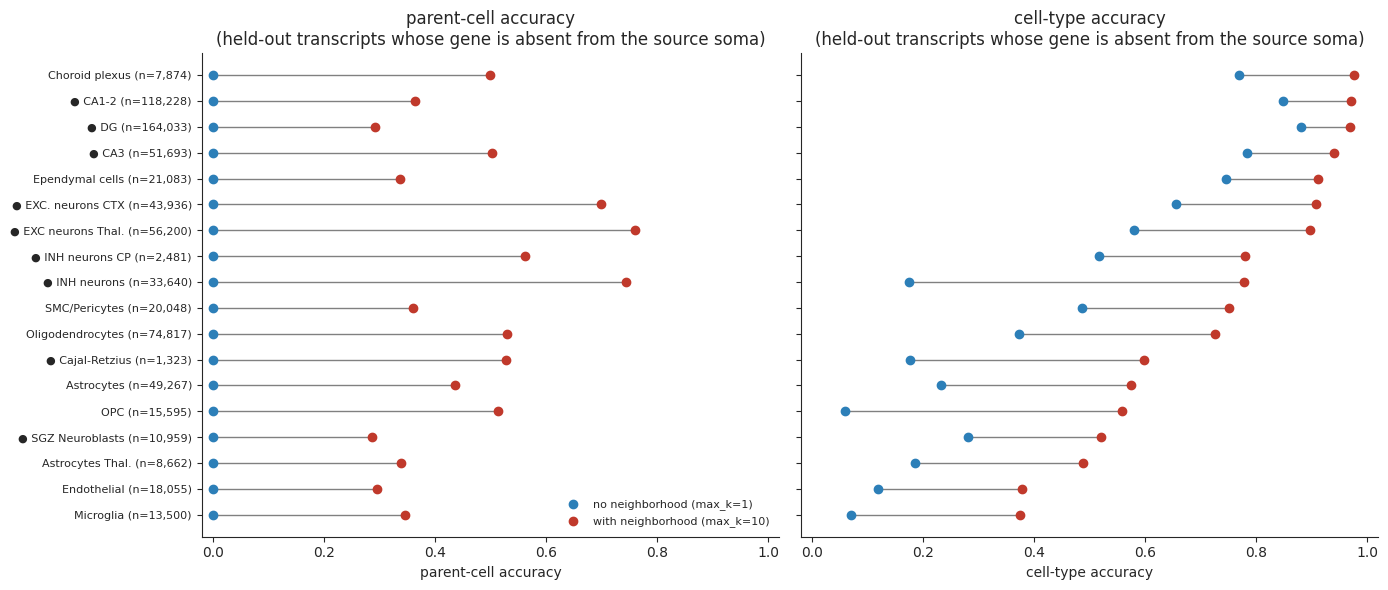

● = neuronal type
        k1__parent_ok  k10__parent_ok  k1__type_ok  k10__type_ok
neuron                                                          
False             0.0           0.438        0.334         0.652
True              0.0           0.457        0.740         0.927


In [7]:
# Per true cell type, gene-absent queries only (density 1.0)
ga = bench[(bench.density == 1.0) & bench.gene_absent_from_soma]
per_ct = ga.groupby('true_ct').agg(n=('true_row', 'size'), parent_no=('k1__parent_ok', 'mean'), parent_with=('k10__parent_ok', 'mean'),
                                   type_no=('k1__type_ok', 'mean'), type_with=('k10__type_ok', 'mean'))
per_ct['neuron'] = per_ct.index.isin(NEURON_TYPES)
per_ct = per_ct.sort_values('type_with')
per_ct.to_csv(saving_path / 'G2_gene_absent_by_celltype.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
y = np.arange(len(per_ct))
for ax, (a, b, t) in zip(axes, [('parent_no', 'parent_with', 'parent-cell accuracy'), ('type_no', 'type_with', 'cell-type accuracy')]):
    ax.hlines(y, per_ct[a], per_ct[b], color='grey', lw=1)
    ax.scatter(per_ct[a], y, color=MODE_COL['no_neighbors'], label=MODE_LABEL['no_neighbors'], zorder=3)
    ax.scatter(per_ct[b], y, color=MODE_COL['with_neighbors'], label=MODE_LABEL['with_neighbors'], zorder=3)
    ax.set(xlabel=t, xlim=(-0.02, 1.02), title=f'{t}\n(held-out transcripts whose gene is absent from the source soma)')
axes[0].set_yticks(y); axes[0].set_yticklabels([f"{'● ' if n else ''}{t} (n={c:,})" for t, n, c in zip(per_ct.index, per_ct.neuron, per_ct.n)], fontsize=8)
axes[0].legend(frameon=False, fontsize=8, loc='lower right')
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'G2_gene_absent_by_celltype.pdf'); plt.show()
print('● = neuronal type')
print(ga.groupby('neuron')[['k1__parent_ok', 'k10__parent_ok', 'k1__type_ok', 'k10__type_ok']].mean().round(3))

In [8]:
# Rescue depends on local uRNA density: the prior only switches on above the ambient floor (k_prod > 1)
bk = bench[bench.density == 1.0].groupby(['gene_absent_from_soma', 'k_prod'])[['k1__parent_ok', 'k10__parent_ok', 'k1__type_ok', 'k10__type_ok']].mean()
bk.columns = ['parent acc, no nbhd', 'parent acc, with nbhd', 'type acc, no nbhd', 'type acc, with nbhd']
bk.round(3)

parent acc, no nbhd  parent acc, with nbhd  \
gene_absent_from_soma k_prod                                               
False                 1                     0.883                  0.883   
                      2                     0.811                  0.778   
                      3                     0.787                  0.728   
                      4                     0.761                  0.688   
                      6                     0.743                  0.658   
                      7                     0.736                  0.643   
                      8                     0.734                  0.634   
                      10                    0.741                  0.638   
True                  1                     0.000                  0.000   
                      2                     0.000                  0.313   
                      3                     0.000                  0.442   
                      4                     0.000                  0.498   
                      6                     0.000                  0.526   
                      7                     0.000                  0.520   
                      8                     0.000                  0.517   
                      10                    0.000                  0.516   

                              type acc, no nbhd  type acc, with nbhd  
gene_absent_from_soma k_prod                                          
False                 1                   0.970                0.970  
                      2                   0.964                0.955  
                      3                   0.962                0.950  
                      4                   0.961                0.947  
                      6                   0.960                0.946  
                      7                   0.961                0.945  
                      8                   0.960                0.944  
                      10                  0.957                0.939  
True                  1                   0.364                0.364  
                      2                   0.488                0.685  
                      3                   0.541                0.803  
                      4                   0.584                0.866  
                      6                   0.616                0.902  
                      7                   0.642                0.912  
                      8                   0.657                0.918  
                      10                  0.670                0.915

## 3. Real data: what the original logic does with these transcripts
On the 8.39 M real extracellular transcripts there's no ground truth, but we can see the failure mode directly:
when the gene isn't expressed by nearby cells, the gene-only logic either sends most of the mass to the residual (score < `min_score` = 0.2, i.e. dropped from figures)
or jumps to a more distant cell that happens to express the gene.

In [9]:
real['k_bin'] = pd.cut(real['k_prod'], [0, 1, 3, 6, 9, 10], labels=['1', '2-3', '4-6', '7-9', '10'])
nb = real[real.k_prod > 1]
lost_no = nb['no_neighbors__score'] < 0.2
lost_with = nb['with_neighbors__score'] < 0.2
rescued = lost_no & ~lost_with
print(f"uRNA in dense clouds (k>1): {len(nb):,} ({len(nb) / len(real):.1%} of all uRNA)")
print(f"  below min_score (effectively bias term)  no nbhd: {lost_no.mean():.1%}   with nbhd: {lost_with.mean():.1%}")
print(f"  rescued (lost without -> score >= 0.2 with): {rescued.mean():.1%}   newly lost: {(~lost_no & lost_with).mean():.1%}")
print(f"  of the rescued, parent does NOT express the transcript's own gene: {(~nb.loc[rescued, 'with_neighbors__gene_expr_in_parent']).mean():.1%}")
print(f"  of the rescued, median distance to parent  no nbhd: {nb.loc[rescued, 'no_neighbors__dist'].median():.1f} µm  "
      f"with nbhd: {nb.loc[rescued, 'with_neighbors__dist'].median():.1f} µm")

g = real.groupby('k_bin', observed=True)
tab = pd.DataFrame({'n': g.size(), 'score<0.2 no nbhd': g['no_neighbors__score'].apply(lambda s: (s < 0.2).mean()),
                    'score<0.2 with nbhd': g['with_neighbors__score'].apply(lambda s: (s < 0.2).mean()),
                    'median dist no nbhd (µm)': g['no_neighbors__dist'].median(), 'median dist with nbhd (µm)': g['with_neighbors__dist'].median()})
tab.to_csv(saving_path / 'G3_real_lost_by_k.csv')
tab.round(3)

uRNA in dense clouds (k>1): 2,507,211 (29.9% of all uRNA)
  below min_score (effectively bias term)  no nbhd: 49.1%   with nbhd: 40.8%
  rescued (lost without -> score >= 0.2 with): 13.0%   newly lost: 4.7%
  of the rescued, parent does NOT express the transcript's own gene: 98.7%
  of the rescued, median distance to parent  no nbhd: 14.6 µm  with nbhd: 3.1 µm


,n,score<0.2 no nbhd,score<0.2 with nbhd,median dist no nbhd (µm),median dist with nbhd (µm)
k_bin,,,,,
1,5881259,0.741,0.741,13.009,13.010
2-3,934900,0.544,0.471,7.542,5.587
4-6,656518,0.480,0.388,6.371,4.543
7-9,439325,0.449,0.358,5.871,4.288
10,476468,0.442,0.362,5.731,4.338


In [10]:
# Neurite-localized mRNAs (dendritic / axonal) present in the 5k panel
NEURITE = ['Shank3', 'Arc', 'Fmr1', 'Bdnf', 'Homer1', 'Nefh', 'Nefm', 'Gap43', 'Grin2b', 'Grin1', 'Grin2a', 'Dlg4', 'Tubb3', 'Kif5a',
           'Nefl', 'Map2', 'Stmn2', 'Syn1', 'Camk2b', 'Camk2a', 'Snap25', 'Cyfip2', 'Ptk2b']
gbt = {m: pd.read_csv(res_dir / f"real_gene_by_type_{m}.csv", index_col=0) for m in MODES}
rows = []
for gname in NEURITE:
    s = nb[nb.gene == gname]
    rows.append({'gene': gname, 'n uRNA (k>1)': len(s),
                 'score<0.2 no nbhd': (s['no_neighbors__score'] < 0.2).mean(), 'score<0.2 with nbhd': (s['with_neighbors__score'] < 0.2).mean(),
                 'median dist no nbhd': s['no_neighbors__dist'].median(), 'median dist with nbhd': s['with_neighbors__dist'].median(),
                 'parent lacks gene (with nbhd)': 1 - s['with_neighbors__gene_expr_in_parent'].mean(),
                 'neuronal mass no nbhd': gbt['no_neighbors'].loc[gname, NEURON_TYPES].sum() / gbt['no_neighbors'].loc[gname].sum(),
                 'neuronal mass with nbhd': gbt['with_neighbors'].loc[gname, NEURON_TYPES].sum() / gbt['with_neighbors'].loc[gname].sum()})
neur = pd.DataFrame(rows).set_index('gene').sort_values('parent lacks gene (with nbhd)', ascending=False)
neur.to_csv(saving_path / 'G3_neurite_genes.csv')
neur.round(3)

,n uRNA (k>1),score<0.2 no nbhd,score<0.2 with nbhd,median dist no nbhd,median dist with nbhd,parent lacks gene (with nbhd),neuronal mass no nbhd,neuronal mass with nbhd
gene,,,,,,,,
Shank3,1501,0.604,0.494,9.127,5.569,0.439,0.540,0.554
Fmr1,819,0.519,0.387,7.408,4.513,0.431,0.677,0.661
Nefh,1535,0.560,0.512,7.946,6.010,0.314,0.750,0.724
Bdnf,716,0.401,0.339,5.483,4.486,0.307,0.906,0.864
Arc,1867,0.473,0.422,6.426,5.045,0.296,0.686,0.677
Nefm,2050,0.459,0.439,6.440,5.304,0.271,0.839,0.807
Homer1,1065,0.392,0.355,5.351,4.317,0.257,0.855,0.832
Gap43,2430,0.445,0.428,6.153,5.080,0.220,0.741,0.721
Grin2b,2292,0.399,0.381,5.358,4.636,0.193,0.877,0.841


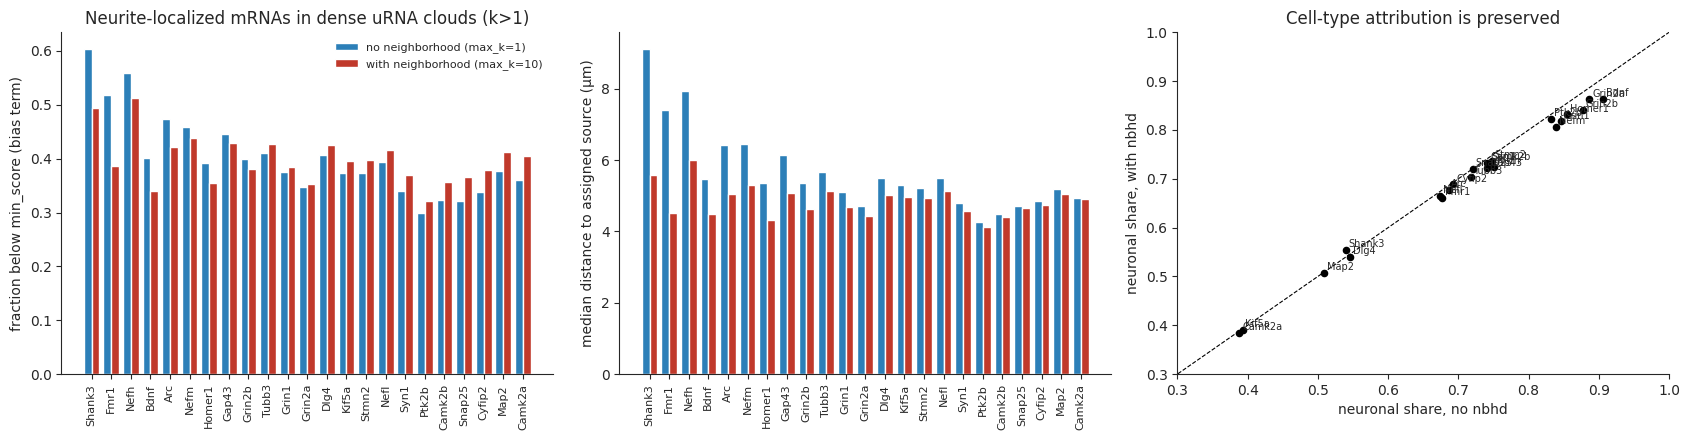

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.arange(len(neur))
for ax, (a, b, yl) in zip(axes[:2], [('score<0.2 no nbhd', 'score<0.2 with nbhd', 'fraction below min_score (bias term)'),
                                     ('median dist no nbhd', 'median dist with nbhd', 'median distance to assigned source (µm)')]):
    ax.bar(x - 0.2, neur[a], 0.4, color=MODE_COL['no_neighbors'], label=MODE_LABEL['no_neighbors'])
    ax.bar(x + 0.2, neur[b], 0.4, color=MODE_COL['with_neighbors'], label=MODE_LABEL['with_neighbors'])
    ax.set_xticks(x); ax.set_xticklabels(neur.index, rotation=90, fontsize=8); ax.set_ylabel(yl)
axes[0].legend(frameon=False, fontsize=8); axes[0].set_title('Neurite-localized mRNAs in dense uRNA clouds (k>1)')
axes[2].scatter(neur['neuronal mass no nbhd'], neur['neuronal mass with nbhd'], c='k', s=20)
for gname, r in neur.iterrows():
    axes[2].annotate(gname, (r['neuronal mass no nbhd'], r['neuronal mass with nbhd']), fontsize=7, xytext=(2, 2), textcoords='offset points')
axes[2].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[2].set(xlabel='neuronal share, no nbhd', ylabel='neuronal share, with nbhd', title='Cell-type attribution is preserved', xlim=(0.3, 1), ylim=(0.3, 1))
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'G3_neurite_genes.pdf'); plt.show()

## 4. Cost and limits (to state honestly)

In [12]:
cost = bench[(bench.density == 1.0)].groupby('gene_absent_from_soma')[['k1__parent_ok', 'k10__parent_ok', 'k1__type_ok', 'k10__type_ok']].mean()
cost['n share'] = bench[bench.density == 1.0]['gene_absent_from_soma'].value_counts(normalize=True)
cost.columns = ['parent no', 'parent with', 'type no', 'type with', 'share of queries']
print('Benchmark (truncated expression, density 1.0):'); display(cost.round(3))
allq = bench[bench.density == 1.0][['k1__parent_ok', 'k10__parent_ok', 'k1__type_ok', 'k10__type_ok']].mean()
print('All held-out queries:', allq.round(3).to_dict())
lowk = bench[(bench.density == 1.0) & bench.gene_absent_from_soma & (bench.k_prod == 1)]
print(f"Gene-absent queries at ambient density (k=1, prior inactive): {len(lowk) / (bench.density == 1.0).sum():.1%} of all queries, "
      f"type acc {lowk['k10__type_ok'].mean():.3f}")

Benchmark (truncated expression, density 1.0):


,parent no,parent with,type no,type with,share of queries
gene_absent_from_soma,,,,,
False,0.757,0.672,0.959,0.945,0.483
True,0.000,0.451,0.609,0.839,0.517


All held-out queries: {'k1__parent_ok': 0.366, 'k10__parent_ok': 0.557, 'k1__type_ok': 0.778, 'k10__type_ok': 0.89}
Gene-absent queries at ambient density (k=1, prior inactive): 5.2% of all queries, type acc 0.364


## Summary

* **Mechanism (code).** With max_k=1 the weight of any candidate lacking the transcript's gene is exactly 0
  (`match_count / n_q` in `_core_scoring_engine_chunk`). The neighborhood prior replaces the single gene by the genes of the
  $k$ nearest extracellular transcripts ($k$ scaled by `enrichment_over_random`), so a soma lacking that one gene can still be the source if it
  expresses the co-localized genes.
* **Worked example.** A dendritic *Shank3* uRNA 0.5 µm from a neuron with zero somatic *Shank3*: without the neighborhood ~all mass goes to the bias term
  (best score ≈ 0.0003, nominal parent 21 µm away). With it, the transcript is assigned to the adjacent neuron (score 0.86).
* **Ground truth.** About half of held-out peripheral transcripts have a gene that is absent from the remaining soma (the reviewer's scenario).
  The original logic recovers **0%** of their parents by construction (53% fall below `min_score`); the neighborhood prior recovers 45% of parents,
  raises cell-type accuracy from 0.61 to 0.84 and cuts the "lost" fraction to 17%. For neuronal sources, cell-type accuracy goes from 0.74 to 0.93.
  Over all held-out transcripts, parent accuracy rises from 0.37 to 0.56 and cell-type accuracy from 0.78 to 0.89.
* **Real data.** Among uRNA in dense clouds (k>1, 30% of uRNA), the fraction below `min_score` drops from 49% to 41%: 13% are rescued vs 4.7% newly lost.
  98.7% of the rescued are assigned to a cell that does **not** express their own gene, and their source moves from a median 14.6 µm to 3.1 µm away,
  which is exactly the protrusion-next-to-soma case. The largest rescue is for sparsely detected neurite mRNAs (*Shank3*, *Fmr1*, *Bdnf*, *Homer1*, *Arc*:
  sources 1–4 µm closer, 5–13 pp fewer lost). For abundant ones (*Camk2a*, *Snap25*) the soma already expresses the gene and the prior slightly dilutes the score.
  Their neuronal attribution is unchanged in all cases, so the prior doesn't create spurious neuronal signal.
* **Cost/limits.** When the gene *is* in the source soma, parent accuracy drops slightly (≈0.76 → 0.67; type accuracy 0.96 → 0.95)
  because neighbors dilute a perfect single-gene match. The prior is off at ambient density (k=1), so isolated extrasomatic transcripts in sparse regions remain hard.
